# Inlet condition: Dirichlet against Danckwerts

Figures for the reruns of `generate.py` (see `README.md`). RUPTURA results are solid lines, Dirichlet in the light
and Danckwerts in the full colour of a run; the digitized experiments of Stampi-Bombelli et al. (2024) are dashed
lines with open markers. Breakthrough times and outlet differences for every case are in `comparison.csv`
(`compare.py`).

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from matplotlib.lines import Line2D

ROOT = Path.cwd()
SIMULATIONS = ROOT / "simulations"
REFERENCE = ROOT.parent.parent / "stampi-bombelli" / "reference_digitized"
FIGURES = ROOT / "figures"
FIGURES.mkdir(exist_ok=True)

plt.style.use("default")
plt.rcParams.update({
    "figure.figsize": (8, 6),
    "savefig.dpi": 300,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "axes.labelsize": 14,
    "legend.fontsize": 14,
    "axes.titlesize": 16,
    "lines.linewidth": 2.0,
    "axes.grid": False,
    "axes.labelpad": 6.0,
})

INLETS = ("dirichlet", "danckwerts")
MARKERS = ("o", "s", "^", "D")


def read_outlet(directory, component="CO2"):
    """Time in s and outlet mole fraction normalized by the inlet one, y_out/y_in."""
    path = next(Path(directory).glob(f"component_*_{component}.data"))
    frame = pd.read_csv(path, comment="#", sep=r"\s+", header=None, usecols=[1, 2, 5], names=["t", "z", "y"])
    z = frame["z"].to_numpy()
    restarts = np.flatnonzero(z[1:] < z[:-1])
    nodes = int(restarts[0]) + 1 if restarts.size else z.size
    outputs = z.size // nodes
    t = frame["t"].to_numpy()[: outputs * nodes].reshape(outputs, nodes)[:, 0] * 60.0
    y = frame["y"].to_numpy()[: outputs * nodes].reshape(outputs, nodes)
    return t, np.divide(y[:, -1], y[:, 0], out=np.zeros(outputs), where=y[:, 0] > 0.0)


def read_reference(case):
    """Digitized outlet CO2 fraction (normalized by the feed) of Stampi-Bombelli et al., Figure 4."""
    frame = pd.read_csv(REFERENCE / f"figure4_{case}.csv")
    return frame["time_s"].to_numpy(), frame["outlet_fraction"].to_numpy()


def breakthrough_time(t, ratio, level=0.5):
    """First crossing of the normalized outlet mole fraction, linear interpolation."""
    i = int(np.argmax(ratio >= level))
    if ratio[i] < level:
        return np.nan
    if i == 0:
        return t[0]
    return t[i - 1] + (level - ratio[i - 1]) * (t[i] - t[i - 1]) / (ratio[i] - ratio[i - 1])


def lighter(color, amount=0.55):
    """Blend a colour with white."""
    return tuple(1.0 - amount * (1.0 - c) for c in to_rgb(color))

## 5.6% CO$_2$ in the monolith, literature $D_L$ (the paper's Monoliths figure)

monolith_5.6pct_0p02mmol     dirichlet  t50 =   1344.5 s   experiment   1516.5 s
monolith_5.6pct_0p02mmol     danckwerts t50 =   1604.2 s   experiment   1516.5 s


monolith_5.6pct_0p06mmol     dirichlet  t50 =    469.8 s   experiment    510.4 s
monolith_5.6pct_0p06mmol     danckwerts t50 =    498.2 s   experiment    510.4 s


monolith_5.6pct_0p18mmol     dirichlet  t50 =    158.7 s   experiment    181.8 s
monolith_5.6pct_0p18mmol     danckwerts t50 =    162.3 s   experiment    181.8 s


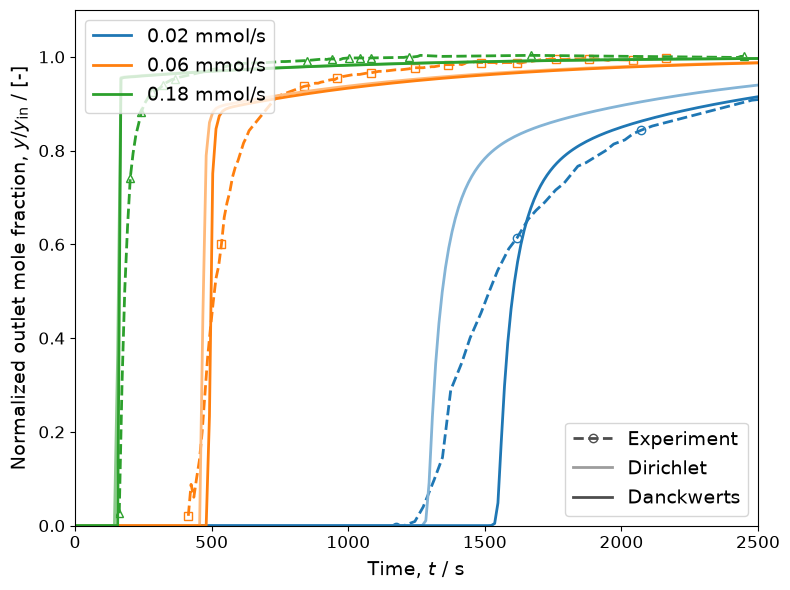

In [2]:
# Monolith, 5.6% CO2, D_L from the literature correlations
cases = [('monolith_5.6pct_0p02mmol', '0.02 mmol/s'), ('monolith_5.6pct_0p06mmol', '0.06 mmol/s'), ('monolith_5.6pct_0p18mmol', '0.18 mmol/s')]
fig, ax = plt.subplots()
for index, (case, label) in enumerate(cases):
    color = f"C{index}"
    t_ref, y_ref = read_reference(case)
    ax.plot(t_ref, y_ref, linestyle="--", marker=MARKERS[index], markerfacecolor="none", markevery=max(1, len(t_ref) // 12),
            color=color)
    for inlet in INLETS:
        directory = SIMULATIONS / inlet / "stampi-bombelli" / "dl_from_literature" / case
        if not (directory / "run.log").is_file():
            continue
        t, ratio = read_outlet(directory)
        ax.plot(t, ratio, color=lighter(color) if inlet == "dirichlet" else color, linestyle="-")
        print(f"{case:28s} {inlet:10s} t50 = {breakthrough_time(t, ratio):8.1f} s   experiment "
              f"{breakthrough_time(t_ref, y_ref):8.1f} s")
ax.set_xlim(0.0, 2500.0)
ax.set_ylim(0.0, 1.1)
ax.set_xlabel("Time, $t$ / s")
ax.set_ylabel(r"Normalized outlet mole fraction, $y/y_{\mathrm{in}}$ / [-]")
flows = ax.legend([Line2D([], [], color=f"C{i}") for i in range(len(cases))], [label for _, label in cases],
                  loc="upper left")
ax.add_artist(flows)
ax.legend([Line2D([], [], color="0.3", linestyle="--", marker="o", markerfacecolor="none"),
           Line2D([], [], color=lighter("0.3")), Line2D([], [], color="0.3")],
          ["Experiment", "Dirichlet", "Danckwerts"], loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "monolith_5p6pct_dl_literature.pdf", dpi=300)
plt.show()

## 5.6% CO$_2$ in the monolith, $D_L$ fitted by Stampi-Bombelli et al. ($vL/D_L$ 0.3–2)

monolith_5.6pct_0p02mmol     dirichlet  t50 =      nan s   experiment   1516.5 s
monolith_5.6pct_0p02mmol     danckwerts t50 =      nan s   experiment   1516.5 s
monolith_5.6pct_0p06mmol     dirichlet  t50 =    144.4 s   experiment    510.4 s


monolith_5.6pct_0p06mmol     danckwerts t50 =    484.5 s   experiment    510.4 s
monolith_5.6pct_0p18mmol     dirichlet  t50 =     90.4 s   experiment    181.8 s


monolith_5.6pct_0p18mmol     danckwerts t50 =    154.3 s   experiment    181.8 s


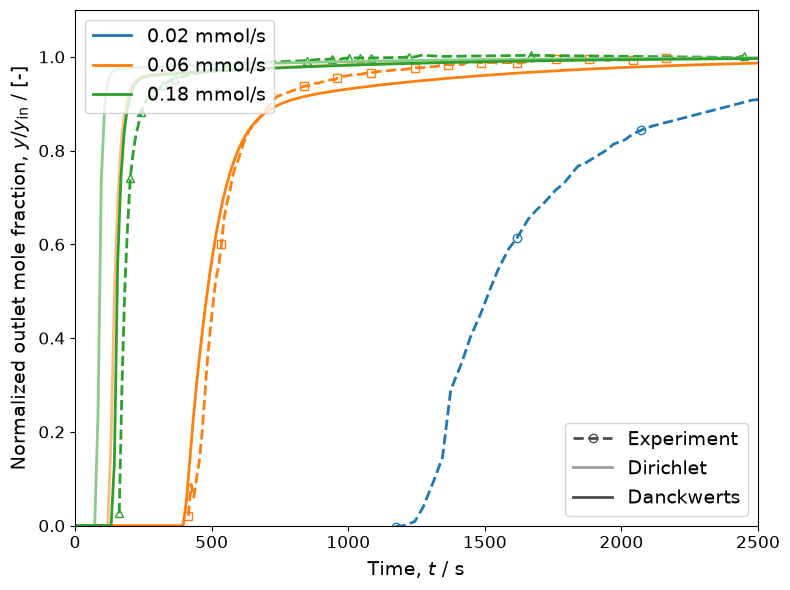

In [3]:
# Monolith, 5.6% CO2, D_L fitted by Stampi-Bombelli et al.
cases = [('monolith_5.6pct_0p02mmol', '0.02 mmol/s'), ('monolith_5.6pct_0p06mmol', '0.06 mmol/s'), ('monolith_5.6pct_0p18mmol', '0.18 mmol/s')]
fig, ax = plt.subplots()
for index, (case, label) in enumerate(cases):
    color = f"C{index}"
    t_ref, y_ref = read_reference(case)
    ax.plot(t_ref, y_ref, linestyle="--", marker=MARKERS[index], markerfacecolor="none", markevery=max(1, len(t_ref) // 12),
            color=color)
    for inlet in INLETS:
        directory = SIMULATIONS / inlet / "stampi-bombelli" / "dl_from_stampibombelli" / case
        if not (directory / "run.log").is_file():
            continue
        t, ratio = read_outlet(directory)
        ax.plot(t, ratio, color=lighter(color) if inlet == "dirichlet" else color, linestyle="-")
        print(f"{case:28s} {inlet:10s} t50 = {breakthrough_time(t, ratio):8.1f} s   experiment "
              f"{breakthrough_time(t_ref, y_ref):8.1f} s")
ax.set_xlim(0.0, 2500.0)
ax.set_ylim(0.0, 1.1)
ax.set_xlabel("Time, $t$ / s")
ax.set_ylabel(r"Normalized outlet mole fraction, $y/y_{\mathrm{in}}$ / [-]")
flows = ax.legend([Line2D([], [], color=f"C{i}") for i in range(len(cases))], [label for _, label in cases],
                  loc="upper left")
ax.add_artist(flows)
ax.legend([Line2D([], [], color="0.3", linestyle="--", marker="o", markerfacecolor="none"),
           Line2D([], [], color=lighter("0.3")), Line2D([], [], color="0.3")],
          ["Experiment", "Dirichlet", "Danckwerts"], loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "monolith_5p6pct_dl_fitted.pdf", dpi=300)
plt.show()

## 400 ppm CO$_2$ in the monolith, $D_L$ fitted by Stampi-Bombelli et al. ($vL/D_L$ 0.8–2)

monolith_400ppm_0p18mmol     dirichlet  t50 =   7779.9 s   experiment  11019.0 s
monolith_400ppm_0p18mmol     danckwerts t50 =  13410.1 s   experiment  11019.0 s


monolith_400ppm_1mmol        dirichlet  t50 =   1271.9 s   experiment   2003.5 s
monolith_400ppm_1mmol        danckwerts t50 =   2268.8 s   experiment   2003.5 s


monolith_400ppm_2mmol        dirichlet  t50 =    414.0 s   experiment    878.7 s
monolith_400ppm_2mmol        danckwerts t50 =   1063.5 s   experiment    878.7 s


monolith_400ppm_3mmol        dirichlet  t50 =    200.3 s   experiment    552.4 s
monolith_400ppm_3mmol        danckwerts t50 =    683.2 s   experiment    552.4 s


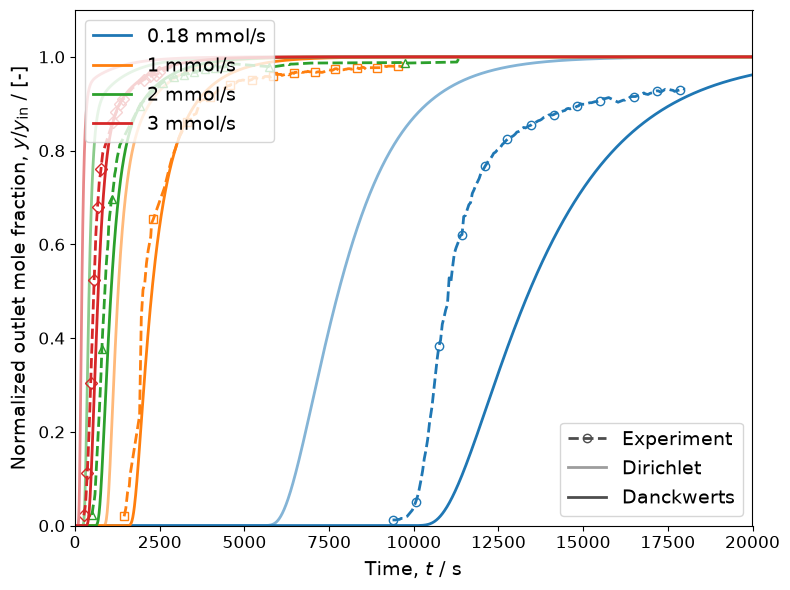

In [4]:
# Monolith, 400 ppm CO2, D_L fitted by Stampi-Bombelli et al.
cases = [('monolith_400ppm_0p18mmol', '0.18 mmol/s'), ('monolith_400ppm_1mmol', '1 mmol/s'), ('monolith_400ppm_2mmol', '2 mmol/s'), ('monolith_400ppm_3mmol', '3 mmol/s')]
fig, ax = plt.subplots()
for index, (case, label) in enumerate(cases):
    color = f"C{index}"
    t_ref, y_ref = read_reference(case)
    ax.plot(t_ref, y_ref, linestyle="--", marker=MARKERS[index], markerfacecolor="none", markevery=max(1, len(t_ref) // 12),
            color=color)
    for inlet in INLETS:
        directory = SIMULATIONS / inlet / "stampi-bombelli" / "dl_from_stampibombelli" / case
        if not (directory / "run.log").is_file():
            continue
        t, ratio = read_outlet(directory)
        ax.plot(t, ratio, color=lighter(color) if inlet == "dirichlet" else color, linestyle="-")
        print(f"{case:28s} {inlet:10s} t50 = {breakthrough_time(t, ratio):8.1f} s   experiment "
              f"{breakthrough_time(t_ref, y_ref):8.1f} s")
ax.set_xlim(0.0, 20000.0)
ax.set_ylim(0.0, 1.1)
ax.set_xlabel("Time, $t$ / s")
ax.set_ylabel(r"Normalized outlet mole fraction, $y/y_{\mathrm{in}}$ / [-]")
flows = ax.legend([Line2D([], [], color=f"C{i}") for i in range(len(cases))], [label for _, label in cases],
                  loc="upper left")
ax.add_artist(flows)
ax.legend([Line2D([], [], color="0.3", linestyle="--", marker="o", markerfacecolor="none"),
           Line2D([], [], color=lighter("0.3")), Line2D([], [], color="0.3")],
          ["Experiment", "Dirichlet", "Danckwerts"], loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "monolith_400ppm_dl_fitted.pdf", dpi=300)
plt.show()

## 5.6% CO$_2$ in the packed bed, $D_L$ fitted by Stampi-Bombelli et al. ($vL/D_L\approx0.04$)

packed_bed_5.6pct_0p5mmol    dirichlet  t50 =     59.5 s   experiment   5657.1 s
packed_bed_5.6pct_0p5mmol    danckwerts t50 =      nan s   experiment   5657.1 s
packed_bed_5.6pct_1mmol      dirichlet  t50 =      9.4 s   experiment   2611.5 s
packed_bed_5.6pct_1mmol      danckwerts t50 =      nan s   experiment   2611.5 s
packed_bed_5.6pct_2mmol      dirichlet  t50 =      7.4 s   experiment   1225.0 s


packed_bed_5.6pct_2mmol      danckwerts t50 =   1448.3 s   experiment   1225.0 s


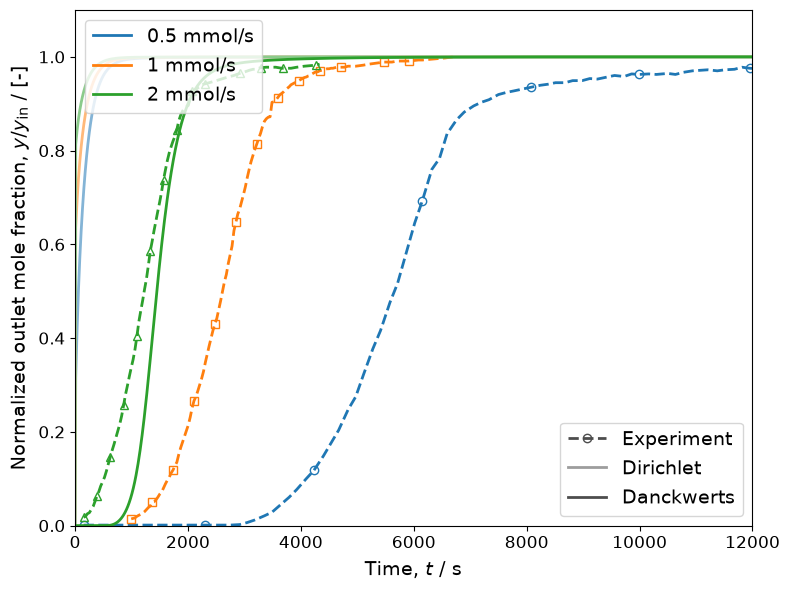

In [5]:
# Packed bed, 5.6% CO2, D_L fitted by Stampi-Bombelli et al.
cases = [('packed_bed_5.6pct_0p5mmol', '0.5 mmol/s'), ('packed_bed_5.6pct_1mmol', '1 mmol/s'), ('packed_bed_5.6pct_2mmol', '2 mmol/s')]
fig, ax = plt.subplots()
for index, (case, label) in enumerate(cases):
    color = f"C{index}"
    t_ref, y_ref = read_reference(case)
    ax.plot(t_ref, y_ref, linestyle="--", marker=MARKERS[index], markerfacecolor="none", markevery=max(1, len(t_ref) // 12),
            color=color)
    for inlet in INLETS:
        directory = SIMULATIONS / inlet / "stampi-bombelli" / "dl_from_stampibombelli" / case
        if not (directory / "run.log").is_file():
            continue
        t, ratio = read_outlet(directory)
        ax.plot(t, ratio, color=lighter(color) if inlet == "dirichlet" else color, linestyle="-")
        print(f"{case:28s} {inlet:10s} t50 = {breakthrough_time(t, ratio):8.1f} s   experiment "
              f"{breakthrough_time(t_ref, y_ref):8.1f} s")
ax.set_xlim(0.0, 12000.0)
ax.set_ylim(0.0, 1.1)
ax.set_xlabel("Time, $t$ / s")
ax.set_ylabel(r"Normalized outlet mole fraction, $y/y_{\mathrm{in}}$ / [-]")
flows = ax.legend([Line2D([], [], color=f"C{i}") for i in range(len(cases))], [label for _, label in cases],
                  loc="upper left")
ax.add_artist(flows)
ax.legend([Line2D([], [], color="0.3", linestyle="--", marker="o", markerfacecolor="none"),
           Line2D([], [], color=lighter("0.3")), Line2D([], [], color="0.3")],
          ["Experiment", "Dirichlet", "Danckwerts"], loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "packed_bed_5p6pct_dl_fitted.pdf", dpi=300)
plt.show()

## T15 axial-dispersion sweep (3.4.3)

Relative change of the CO$_2$ breakthrough time against the run without dispersion, for every dispersion level of
the sensitivity study (the T15 value is 4.3e-6 m$^2$/s).

dirichlet t50(D=0) = 634.7 s; 4.3e-06: -0.0001, 1.0e-05: -0.0002, 1.0e-04: -0.0020, 1.0e-03: -0.0287


danckwerts t50(D=0) = 634.69 s; 4.3e-06: +0.0000, 1.0e-05: +0.0000, 1.0e-04: +0.0004, 1.0e-03: -0.0024


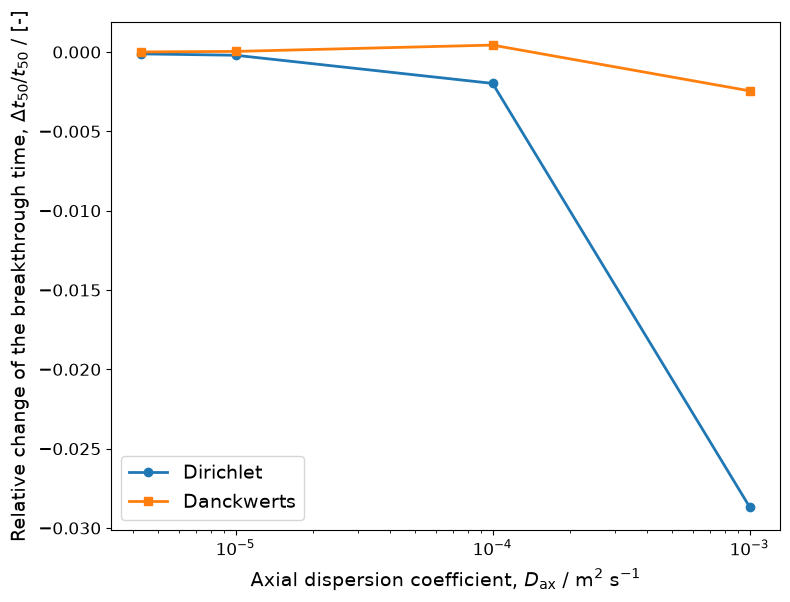

In [6]:
# T15, CO2 t50 against the axial dispersion coefficient, both inlets
levels = {"reference": 4.3e-6, "axial_dispersion_coefficient/1e-5": 1e-5, "axial_dispersion_coefficient/1e-4": 1e-4,
          "axial_dispersion_coefficient/1e-3": 1e-3}
fig, ax = plt.subplots()
for index, inlet in enumerate(INLETS):
    study = SIMULATIONS / inlet / "3.4.3_sensitivity"
    t_zero, ratio_zero = read_outlet(study / "axial_dispersion_coefficient" / "0")
    t50_zero = breakthrough_time(t_zero, ratio_zero)
    dispersion, change = [], []
    for case, value in levels.items():
        t, ratio = read_outlet(study / case)
        dispersion.append(value)
        change.append(breakthrough_time(t, ratio) / t50_zero - 1.0)
    ax.plot(dispersion, change, color=f"C{index}", marker=MARKERS[index], linestyle="-", label=inlet.capitalize())
    print(inlet, "t50(D=0) =", round(t50_zero, 2), "s;", ", ".join(f"{d:.1e}: {c:+.4f}" for d, c in zip(dispersion, change)))
ax.set_xscale("log")
ax.set_xticks([1e-5, 1e-4, 1e-3])
ax.set_xticklabels(["$10^{-5}$", "$10^{-4}$", "$10^{-3}$"])
ax.set_xlabel(r"Axial dispersion coefficient, $D_{\mathrm{ax}}$ / m$^2$ s$^{-1}$")
ax.set_ylabel(r"Relative change of the breakthrough time, $\Delta t_{50}/t_{50}$ / [-]")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES / "t15_dispersion_sweep_t50.pdf", dpi=300)
plt.show()